<div align="center">

<!-- Judul Laporan -->
<h1><strong>TUGAS</strong></h1>
<h2><strong>KECERDASAN ARTIFICIAL UNTUK GEOFISIKA</strong></h2>
<ul style="list-style-type: none; padding-left: 0;">


<!-- Logo Universitas -->
<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<!-- Penulis -->
<h3>Disusun Oleh:</h3>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li style="display:flex; justify-content:space-between;"><span>ANDI AZIZAH</span><span>(H061241005)</span></li>
</ul>
<br><br>
<!-- Departemen dan Fakultas -->
<p><strong>DEPARTEMEN GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong>UNIVERSITAS HASANUDDIN</strong></p>
<p><strong>MAKASSAR</strong></p>

<!-- Tahun -->
<p><strong>2026</strong></p>

</div>

----------

## **OUTPUT PROMPT KECERDASAN ARTIFICIAL MENGGUNAKAN METODE GEOFISIKA**

In [3]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from scipy.signal import find_peaks

# Pengaturan agar hasil dapat direproduksi
SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "figure.figsize": (10, 5),
    "axes.grid": True,
    "grid.alpha": 0.2
})

SIMULATION_LABEL = "DATA SIMULASI — BUKAN DATA LAPANGAN"

def add_simulation_label(fig):
    fig.text(
        0.5, 0.005, SIMULATION_LABEL,
        ha="center", color="darkred",
        fontsize=9, fontweight="bold"
    )

print("Konfigurasi berhasil.")
print("Random seed:", SEED)
print(SIMULATION_LABEL)


Konfigurasi berhasil.
Random seed: 42
DATA SIMULASI — BUKAN DATA LAPANGAN


----

### **1. ERT — Electrical Resistivity Tomography**
Tujuan: menampilkan penampang resistivitas 2D untuk mengidentifikasi zona resistivitas rendah dan tinggi.

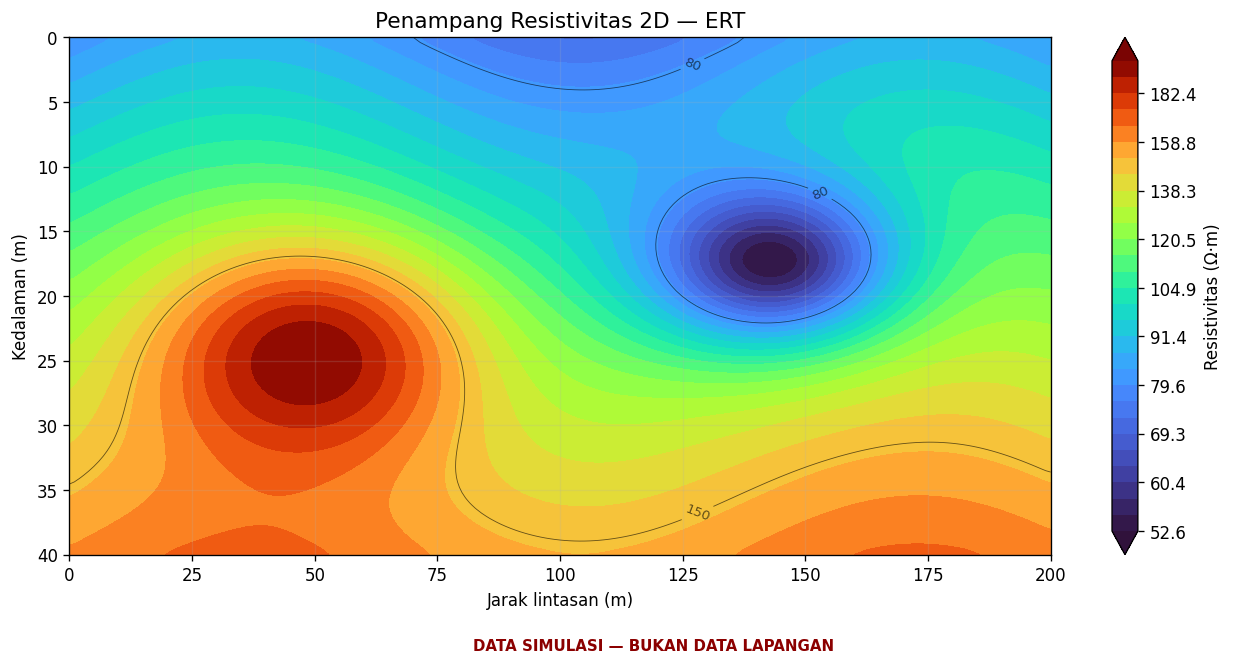

HASIL NUMERIK ERT
Resistivitas minimum : 52.29 Ω·m
Resistivitas maksimum: 200.22 Ω·m
Resistivitas rata-rata: 122.76 Ω·m

INTERPRETASI
Zona konduktif disimulasikan di sekitar x=145 m.
Zona resistif disimulasikan di sekitar x=50 m.
Resistivitas rendah tidak otomatis berarti akuifer.
Diperlukan data geologi, muka air tanah, dan salinitas.


In [4]:

# ==============================================
# PROMPT 1: ELECTRICAL RESISTIVITY TOMOGRAPHY
# DATA SIMULASI
# ==============================================

x = np.linspace(0, 200, 201)
z = np.linspace(0, 40, 101)
X, Z = np.meshgrid(x, z)

# Model latar belakang: resistivitas meningkat dengan kedalaman
rho = 80 + 2.0 * Z + 8 * np.sin(X / 22)

# Zona konduktif: ilustrasi material lempungan/jenuh air
conductive = np.exp(
    -((X - 145) / 28)**2 - ((Z - 18) / 7)**2
)

# Zona resistif: ilustrasi material lebih kompak
resistive = np.exp(
    -((X - 50) / 30)**2 - ((Z - 24) / 8)**2
)

rho = rho - 65 * conductive + 65 * resistive
rho = np.clip(rho, 5, 500)

# Simulasi smoothing seperti tampilan penampang hasil pengolahan
rho_display = gaussian_filter(rho, sigma=1.0)

assert rho_display.shape == X.shape
assert np.all(np.isfinite(rho_display))
assert np.all(rho_display > 0)

fig, ax = plt.subplots(figsize=(11, 5.5))
levels = np.geomspace(rho_display.min(), rho_display.max(), 30)

cf = ax.contourf(
    X, Z, rho_display,
    levels=levels, cmap="turbo", extend="both"
)
cs = ax.contour(
    X, Z, rho_display,
    levels=[20, 40, 80, 150, 250],
    colors="black", linewidths=0.5, alpha=0.6
)
ax.clabel(cs, inline=True, fontsize=8, fmt="%.0f")

ax.invert_yaxis()
ax.set_xlabel("Jarak lintasan (m)")
ax.set_ylabel("Kedalaman (m)")
ax.set_title("Penampang Resistivitas 2D — ERT")
fig.colorbar(cf, ax=ax, label="Resistivitas (Ω·m)")
add_simulation_label(fig)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

print("HASIL NUMERIK ERT")
print(f"Resistivitas minimum : {rho.min():.2f} Ω·m")
print(f"Resistivitas maksimum: {rho.max():.2f} Ω·m")
print(f"Resistivitas rata-rata: {rho.mean():.2f} Ω·m")

print("\nINTERPRETASI")
print("Zona konduktif disimulasikan di sekitar x=145 m.")
print("Zona resistif disimulasikan di sekitar x=50 m.")
print("Resistivitas rendah tidak otomatis berarti akuifer.")
print("Diperlukan data geologi, muka air tanah, dan salinitas.")


----- 


### **2. Seismik Refleksi (Seismic Reflection)**
Tujuan: membuat penampang seismik sintetis untuk memperlihatkan reflektor dan indikasi sesar.


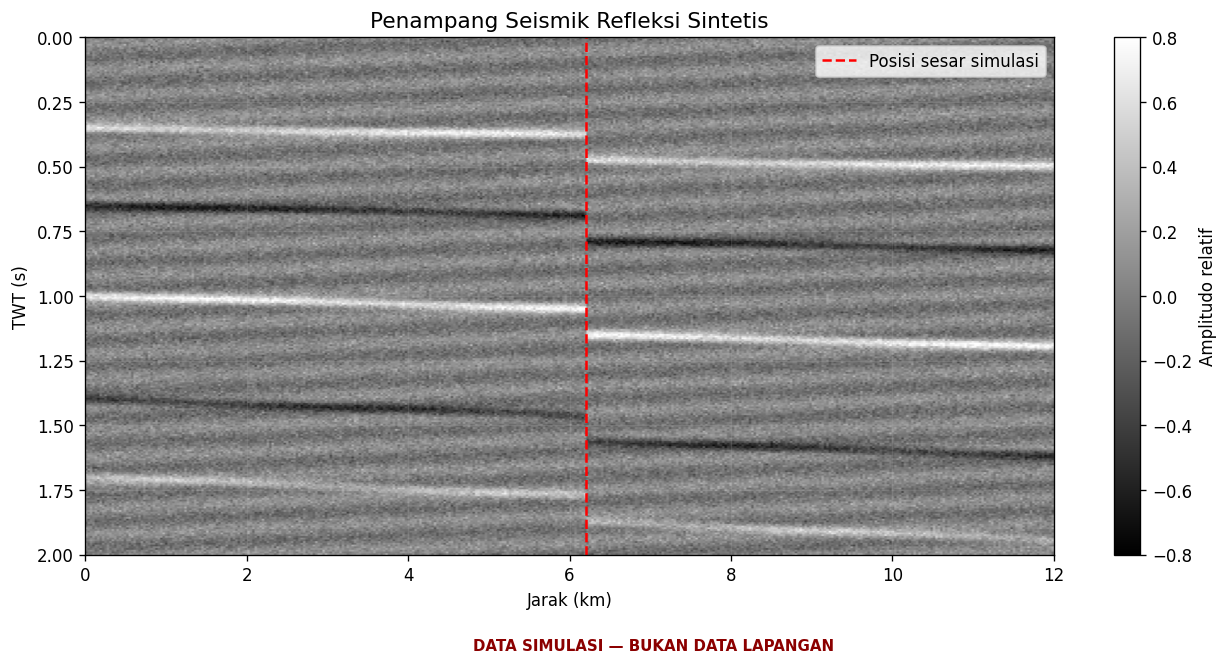

HASIL NUMERIK SEISMIK
Ukuran penampang: (300, 400)
Rentang waktu: 0.00–2.00 s
Posisi sesar yang ditanam dalam model: 6.20 km
Offset waktu yang disimulasikan: 0.10 s

INTERPRETASI
Model memuat lima reflektor dengan offset di sekitar sesar.
Posisi sesar diketahui dari parameter model sintetis.
Data nyata memerlukan pemeriksaan kontinuitas reflektor,
migrasi, multiple, dan kalibrasi sumur bila tersedia.


In [5]:

# ==============================================
# PROMPT 2: SEISMIK REFLEKSI
# DATA SIMULASI
# ==============================================

nx, nt = 400, 300
x = np.linspace(0, 12, nx)
t = np.linspace(0, 2.0, nt)

section = np.zeros((nt, nx))

# Reflektor dengan kemiringan dan offset sesar
horizons = [
    (0.35, 0.004, 0.8),
    (0.65, 0.006, -0.7),
    (1.00, 0.008, 0.9),
    (1.40, 0.010, -0.6),
    (1.70, 0.012, 0.5)
]

fault_x = 6.2
fault_throw = 0.10

for t0, slope, amplitude in horizons:
    for i, xi in enumerate(x):
        offset = fault_throw if xi >= fault_x else 0.0
        arrival = t0 + slope * xi + offset
        wavelet = np.exp(-((t - arrival) / 0.018)**2)
        section[:, i] += amplitude * wavelet

# Tambahan refleksi lemah dan noise
section += 0.15 * np.sin(
    2 * np.pi * (t[:, None] * 10 + x[None, :] * 0.12)
)
section += rng.normal(0, 0.12, section.shape)

# Normalisasi amplitudo
section /= np.max(np.abs(section))

assert section.shape == (nt, nx)
assert np.all(np.isfinite(section))

fig, ax = plt.subplots(figsize=(11, 5.5))
im = ax.imshow(
    section, cmap="gray", aspect="auto",
    extent=[x.min(), x.max(), t.max(), t.min()],
    vmin=-0.8, vmax=0.8
)
ax.axvline(
    fault_x, color="red", linestyle="--",
    linewidth=1.5, label="Posisi sesar simulasi"
)
ax.set_xlabel("Jarak (km)")
ax.set_ylabel("TWT (s)")
ax.set_title("Penampang Seismik Refleksi Sintetis")
ax.legend()
fig.colorbar(im, ax=ax, label="Amplitudo relatif")
add_simulation_label(fig)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

print("HASIL NUMERIK SEISMIK")
print("Ukuran penampang:", section.shape)
print(f"Rentang waktu: {t.min():.2f}–{t.max():.2f} s")
print(f"Posisi sesar yang ditanam dalam model: {fault_x:.2f} km")
print(f"Offset waktu yang disimulasikan: {fault_throw:.2f} s")

print("\nINTERPRETASI")
print("Model memuat lima reflektor dengan offset di sekitar sesar.")
print("Posisi sesar diketahui dari parameter model sintetis.")
print("Data nyata memerlukan pemeriksaan kontinuitas reflektor,")
print("migrasi, multiple, dan kalibrasi sumur bila tersedia.")


---

### **3. GPR — Ground Penetrating Radar**
Radargram dihasilkan dari dua target sintetis berbentuk hiperbola. Kedalaman dihitung menggunakan \(z=v\,t/2\), dengan waktu dalam nanodetik dan kecepatan dalam meter per nanodetik.


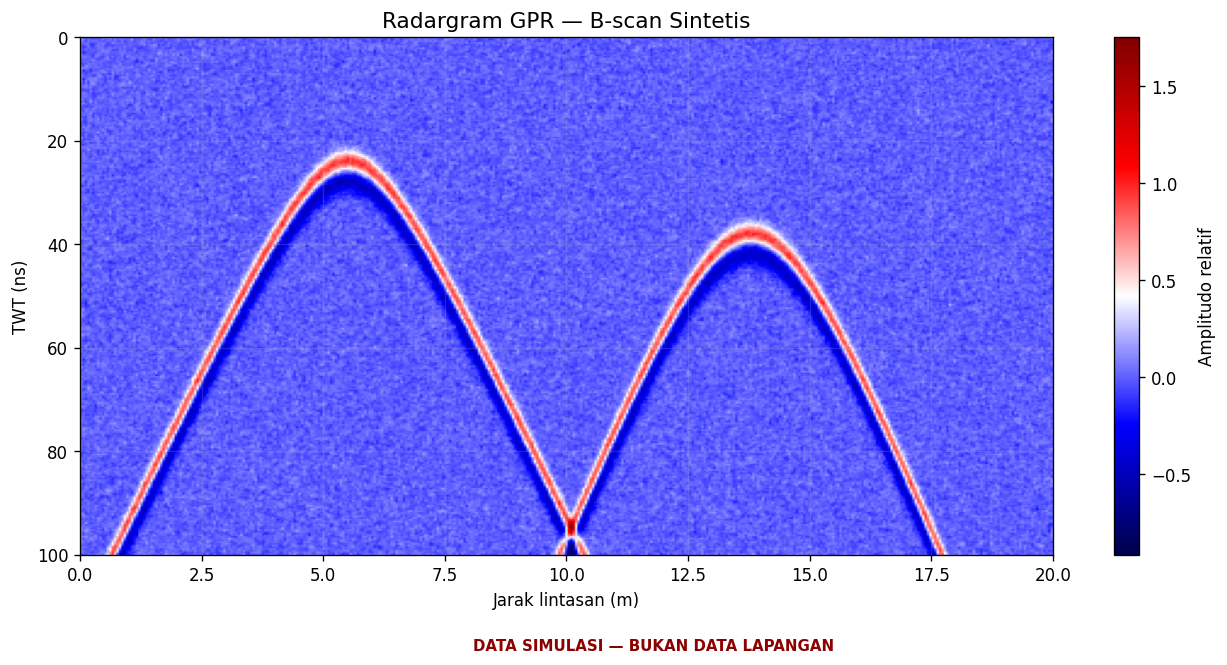

,Target,Posisi (m),TWT (ns),Kecepatan (m/ns),Kedalaman (m)
0,1,5.5,24.0,0.100,1.200
1,2,13.8,38.0,0.085,1.615


INTERPRETASI
Hiperbola dapat menunjukkan objek terpendam atau batas material.
Bentuk anomali tidak cukup untuk memastikan jenis objek.
Kecepatan gelombang perlu dikalibrasi pada material setempat.


In [6]:

# ==============================================
# PROMPT 3: GROUND PENETRATING RADAR
# DATA SIMULASI
# ==============================================

x_gpr = np.linspace(0, 20, 401)
t_ns = np.linspace(0, 100, 301)
Xg, Tg = np.meshgrid(x_gpr, t_ns)

gpr = rng.normal(0, 0.08, Xg.shape)

# Target: (posisi horizontal m, waktu puncak ns, kecepatan m/ns)
targets = [
    (5.5, 24.0, 0.10),
    (13.8, 38.0, 0.085)
]

for x0, t0, velocity in targets:
    hyperbola = np.sqrt(
        t0**2 + (2 * (x_gpr - x0) / velocity)**2
    )
    for i in range(len(x_gpr)):
        gpr[:, i] += (
            np.exp(-((t_ns - hyperbola[i]) / 2.0)**2)
            - 0.5 * np.exp(
                -((t_ns - hyperbola[i] - 3.5) / 2.5)**2
            )
        )

gpr = gaussian_filter(gpr, sigma=(0.6, 0.5))

assert gpr.shape == Xg.shape
assert np.all(np.isfinite(gpr))

fig, ax = plt.subplots(figsize=(11, 5.5))
im = ax.imshow(
    gpr, cmap="seismic", aspect="auto",
    extent=[x_gpr.min(), x_gpr.max(), t_ns.max(), t_ns.min()]
)
ax.set_ylim(100, 0)
ax.set_xlabel("Jarak lintasan (m)")
ax.set_ylabel("TWT (ns)")
ax.set_title("Radargram GPR — B-scan Sintetis")
fig.colorbar(im, ax=ax, label="Amplitudo relatif")
add_simulation_label(fig)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

# Menghitung kedalaman target
hasil_gpr = []
for i, (x0, t0, velocity) in enumerate(targets, start=1):
    depth = velocity * t0 / 2
    hasil_gpr.append({
        "Target": i,
        "Posisi (m)": x0,
        "TWT (ns)": t0,
        "Kecepatan (m/ns)": velocity,
        "Kedalaman (m)": depth
    })

df_gpr = pd.DataFrame(hasil_gpr)
display(df_gpr.round(3))

print("INTERPRETASI")
print("Hiperbola dapat menunjukkan objek terpendam atau batas material.")
print("Bentuk anomali tidak cukup untuk memastikan jenis objek.")
print("Kecepatan gelombang perlu dikalibrasi pada material setempat.")


----

### **4. MASW — Multichannel Analysis of Surface Waves**
Bagian ini menampilkan kurva dispersi serta model kecepatan gelombang geser. Vs30 dihitung dari ketebalan dan kecepatan setiap lapisan hingga kedalaman 30 m.


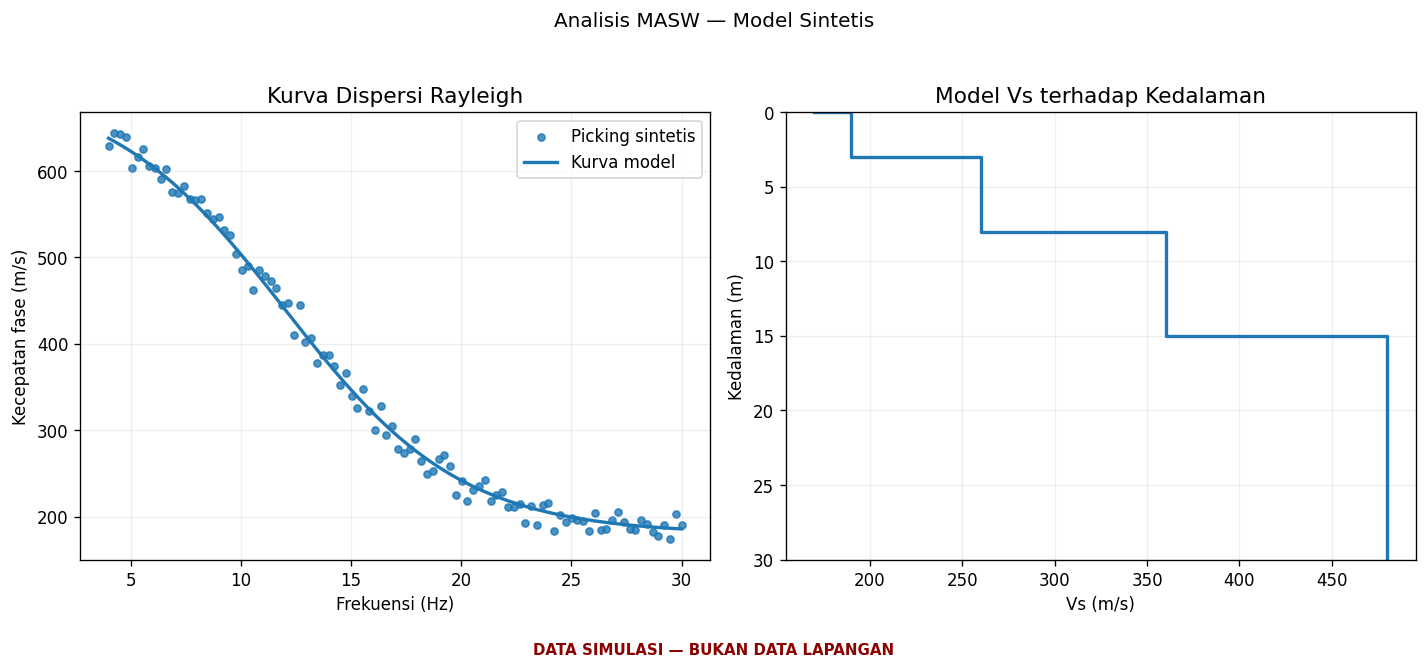

HASIL NUMERIK MASW
Vs30 = 275.03 m/s
RMSE noise terhadap model pembangkit = 10.79 m/s

INTERPRETASI
Model memperlihatkan Vs meningkat dengan kedalaman.
RMSE di sini mengukur noise simulasi terhadap kurva pembangkit,
bukan misfit inversi lapangan.
Klasifikasi situs harus mengikuti standar dan tujuan proyek.


In [7]:

# ==============================================
# PROMPT 4: MASW
# DATA SIMULASI
# ==============================================

frequency = np.linspace(4, 30, 100)

# Kurva dispersi fundamental sintetis
v_phase_model = 180 + 520 / (
    1 + np.exp((frequency - 12) / 4)
)
v_phase_obs = v_phase_model + rng.normal(
    0, 10, len(frequency)
)

# Lapisan Vs sampai kedalaman 30 m
bounds = np.array([0, 3, 8, 15, 25, 30], dtype=float)
vs_layers = np.array([170, 190, 260, 360, 480], dtype=float)

thickness = np.diff(bounds)

# Validasi model
assert len(thickness) == len(vs_layers)
assert np.all(thickness > 0)
assert np.all(vs_layers > 0)

# Vs30 = 30 / sum(hi / Vsi)
vs30 = 30.0 / np.sum(thickness / vs_layers)

fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))

ax[0].scatter(
    frequency, v_phase_obs,
    s=18, alpha=0.8, label="Picking sintetis"
)
ax[0].plot(
    frequency, v_phase_model,
    linewidth=2, label="Kurva model"
)
ax[0].set_xlabel("Frekuensi (Hz)")
ax[0].set_ylabel("Kecepatan fase (m/s)")
ax[0].set_title("Kurva Dispersi Rayleigh")
ax[0].legend()

ax[1].step(
    np.r_[vs_layers, vs_layers[-1]],
    bounds, where="post", linewidth=2
)
ax[1].invert_yaxis()
ax[1].set_xlabel("Vs (m/s)")
ax[1].set_ylabel("Kedalaman (m)")
ax[1].set_title("Model Vs terhadap Kedalaman")
ax[1].set_ylim(30, 0)

fig.suptitle("Analisis MASW — Model Sintetis")
add_simulation_label(fig)
plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.show()

print("HASIL NUMERIK MASW")
print(f"Vs30 = {vs30:.2f} m/s")

# Misfit terhadap kurva dispersi model pembangkit
rmse = np.sqrt(np.mean((v_phase_obs - v_phase_model)**2))
print(f"RMSE noise terhadap model pembangkit = {rmse:.2f} m/s")

print("\nINTERPRETASI")
print("Model memperlihatkan Vs meningkat dengan kedalaman.")
print("RMSE di sini mengukur noise simulasi terhadap kurva pembangkit,")
print("bukan misfit inversi lapangan.")
print("Klasifikasi situs harus mengikuti standar dan tujuan proyek.")


----

### **5. HVSR — Horizontal-to-Vertical Spectral Ratio**
Tujuan: menghasilkan kurva H/V sintetis dengan puncak resonansi, lalu menghitung frekuensi dominan, amplitudo puncak, dan indeks kerentanan relatif.


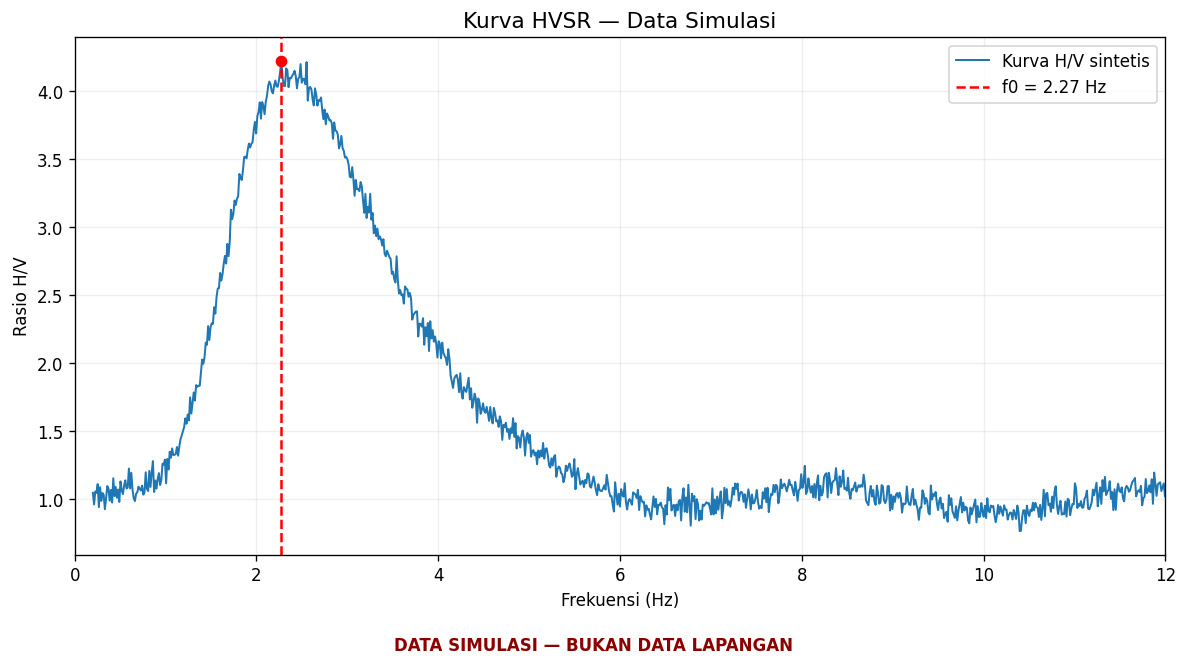

HASIL NUMERIK HVSR
Frekuensi dominan f0 = 2.274 Hz
Amplitudo puncak A0 = 4.222
Indeks kerentanan relatif Kg = 7.840

INTERPRETASI
Puncak H/V menunjukkan frekuensi dominan pada model simulasi.
Kg merupakan indeks relatif, bukan probabilitas kerusakan.
Kelayakan puncak pada data nyata perlu diuji menggunakan
kriteria reliabilitas HVSR dan kestabilan antarsubwindow.


In [8]:

# ==============================================
# PROMPT 5: HVSR / MIKROTREMOR
# DATA SIMULASI
# ==============================================

frequency_hvsr = np.linspace(0.2, 20, 1500)

f0_model = 2.4
A0_model = 4.2

hv_model = 1 + (A0_model - 1) * np.exp(
    -0.5 * (
        (np.log(frequency_hvsr) - np.log(f0_model)) / 0.34
    )**2
)

hv = (
    hv_model
    + 0.10 * np.sin(1.7 * frequency_hvsr)
    + rng.normal(0, 0.06, len(frequency_hvsr))
)
hv = np.clip(hv, 0.5, None)

# Mendeteksi puncak lokal
peaks, properties = find_peaks(
    hv, prominence=0.2, distance=20
)

# Pilih puncak tertinggi dalam rentang evaluasi
valid_peaks = peaks[
    (frequency_hvsr[peaks] >= 0.5)
    & (frequency_hvsr[peaks] <= 10)
]

if len(valid_peaks) == 0:
    raise ValueError("Tidak ditemukan puncak HVSR dalam rentang evaluasi.")

peak_idx = valid_peaks[np.argmax(hv[valid_peaks])]
f0 = frequency_hvsr[peak_idx]
A0 = hv[peak_idx]

# Indeks kerentanan relatif
Kg = A0**2 / f0

assert f0 > 0
assert A0 > 0
assert np.isfinite(Kg)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(
    frequency_hvsr, hv,
    linewidth=1.2, label="Kurva H/V sintetis"
)
ax.axvline(
    f0, color="red", linestyle="--",
    label=f"f0 = {f0:.2f} Hz"
)
ax.scatter([f0], [A0], color="red", zorder=3)
ax.set_xlim(0, 12)
ax.set_xlabel("Frekuensi (Hz)")
ax.set_ylabel("Rasio H/V")
ax.set_title("Kurva HVSR — Data Simulasi")
ax.legend()
fig.text(
    0.5, 0.005, SIMULATION_LABEL,
    ha="center", color="darkred", fontweight="bold"
)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

print("HASIL NUMERIK HVSR")
print(f"Frekuensi dominan f0 = {f0:.3f} Hz")
print(f"Amplitudo puncak A0 = {A0:.3f}")
print(f"Indeks kerentanan relatif Kg = {Kg:.3f}")

print("\nINTERPRETASI")
print("Puncak H/V menunjukkan frekuensi dominan pada model simulasi.")
print("Kg merupakan indeks relatif, bukan probabilitas kerusakan.")
print("Kelayakan puncak pada data nyata perlu diuji menggunakan")
print("kriteria reliabilitas HVSR dan kestabilan antarsubwindow.")
